# Trina's Trinkets Inc. (Trina's)

## A little Introduction
Trina's is a corporation with its headquarters in Utah. She sells many different types of small trinkets and gifts to primarily end consumers but also to wholesalers.

She is currently operating in:
- Utah
- Arizona
- Idaho
- Montana
- Washington
- Wyoming

She plans to expand further throughout the western United States.



# Data Cleaning 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [51]:
file_name = "Analytics_mindset_case_study_solutions_Trinas_Trinkets.xlsx"
df = pd.read_excel(file_name)

df_clean = df.copy()

In [4]:
df_clean.info()
# 394829 Rows 

<class 'pandas.DataFrame'>
RangeIndex: 394829 entries, 0 to 394828
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   TransactionID          394829 non-null  int64         
 1   InvoiceNo              394829 non-null  object        
 2   StockCode              394829 non-null  object        
 3   Quantity               394829 non-null  int64         
 4   UnitPrice              394829 non-null  float64       
 5   CustomerNumber         394829 non-null  int64         
 6   ZipCode                394829 non-null  int64         
 7   State                  394829 non-null  str           
 8   City                   394829 non-null  str           
 9   Revenue                394829 non-null  float64       
 10  SalesTaxOwed           394829 non-null  float64       
 11  InvoiceDate            394829 non-null  datetime64[us]
 12  InvoiceYear            394829 non-null  int64         


In [5]:
anzahlduplikate = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f"Es gibt {anzahlduplikate} duplikate")
# Keine Duplikate

df_clean = df_clean.dropna().reset_index(drop = True)
# 29 Zeilen mit min. 1 Fehlenden Wert

Es gibt 0 duplikate


In [6]:
print(df_clean['Revenue'].describe().round(2))

count    394800.00
mean         20.86
std         428.12
min     -168469.60
25%           4.35
50%          11.80
75%          19.80
max      168469.60
Name: Revenue, dtype: float64


In [7]:
q_high = df_clean['Revenue'].quantile(0.999)# Oder 0.9999 absprache halten
print(df_clean['Revenue'].quantile(0.999))

df_clean = df_clean.loc[df_clean['Revenue'] < q_high].reset_index(drop=True)
# Damit werden die oberen 0,01% gelöscht um mutmaßliche Falsch abbuchungen zu eliminieren

855.5999999999999


In [8]:
year = df_clean[['InvoiceYear']].value_counts()
print(year)
# Jahresdiffernez an Daten

InvoiceYear
2017           360756
2016            25181
Name: count, dtype: int64


In [9]:
print(df_clean['Revenue'].describe().round(2))
# Zu sehen das die Standardabweichung bei Revenue wieder normal ist 
# Von 428 auf 40.45 gesunken 


print(df_clean['Revenue'].max())
# Maximal berücksichtigtes Revenue

count    385937.00
mean         20.18
std          40.45
min           0.06
25%           4.95
50%          12.48
75%          19.80
max         851.76
Name: Revenue, dtype: float64
851.76


# Data Visualization

## Objective

The objective of this section is to analyze the transaction data using visualizations.
The charts help identify the states with the highest profitability, revenue and post-tax profit margin while also examining the influence of different tax burdens on business performance.

This analysis directly addresses the analytical question:

**Based on the 2016–2017 transaction data, which states offer Trina's the best post-tax profitability, and how do the different tax burdens influence this ranking?**

## Total Profit by State

The following chart shows the total profit generated in each state.

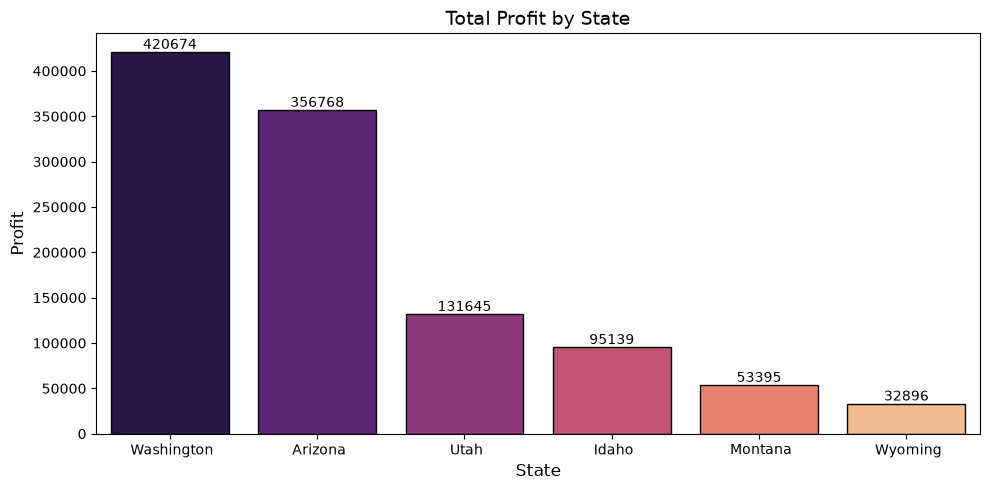

In [59]:
profit_state = (
    df_clean.groupby('State')['Profit']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  

ax1 = sns.barplot(
    data=profit_state,
    x='State',
    y='Profit',
    hue='State',             
    palette='magma',
    legend=False,
    edgecolor='black'
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f')

plt.xlabel("State", fontsize=12)
plt.ylabel("Profit", fontsize=12)
plt.title("Total Profit by State", fontsize=14)
plt.tight_layout()
plt.show()  

### Interpretation

Washington generated the highest total profit, followed by Arizona.
States with lower total profits contributed significantly less to the company's overall profitability.
This indicates that Trina's strongest financial performance is concentrated in only a few states.

## Total Revenue by State

This visualization shows the total revenue generated in each state during the 2016–2017 period.

Revenue reflects the total sales volume before taxes and expenses. Comparing revenue across states helps identify the company's strongest markets and provides additional context for interpreting profitability.

<Figure size 1000x500 with 0 Axes>

[Text(0, 0, '2970836')]

[Text(0, 0, '2512133')]

[Text(0, 0, '925902')]

[Text(0, 0, '671653')]

[Text(0, 0, '375845')]

[Text(0, 0, '232297')]

Text(0.5, 1.0, 'Total Revenue by State')

Text(0.5, 0, 'State')

Text(0, 0.5, 'Revenue')

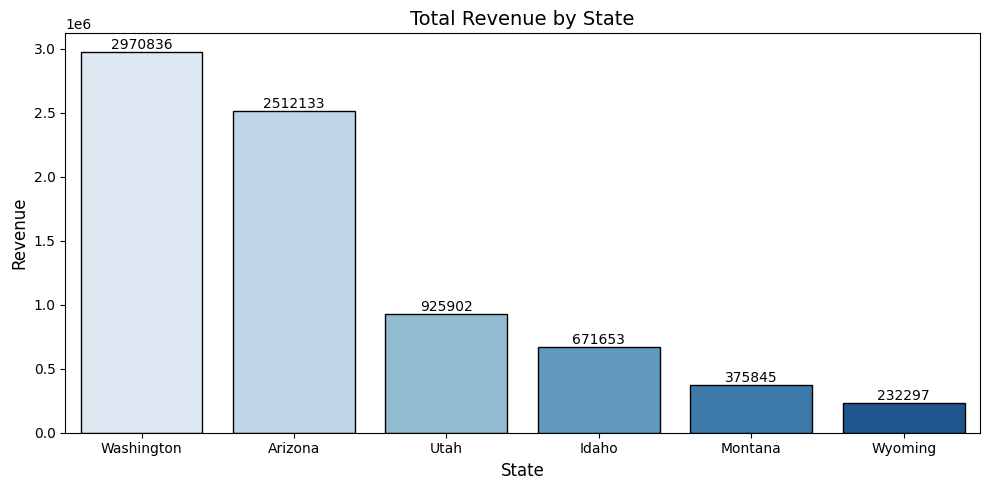

In [10]:
revenue_state = (
    df_clean.groupby("State")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  # WICHTIG: Neues Fenster für Grafik 2

ax2 = sns.barplot(
    data=revenue_state,
    x="State",
    y="Revenue",
    hue="State",
    palette="Blues",
    legend=False,
    edgecolor="black"
)

for container in ax2.containers:
    ax2.bar_label(container, fmt="%.0f")

plt.title("Total Revenue by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Revenue", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The chart shows that Washington generated the highest total revenue, followed by Arizona. These two states clearly outperform the remaining states in terms of sales volume.

Although high revenue does not automatically guarantee high profitability, it provides an important explanation for why Washington and Arizona also rank among the strongest states in terms of overall profit. States with lower revenue contribute less to the company's total financial performance.

## Total Profit by State

The following chart shows the total profit generated in each state.

<Figure size 1000x500 with 0 Axes>

[Text(0, 0, '415917')]

[Text(0, 0, '351699')]

[Text(0, 0, '129626')]

[Text(0, 0, '94031')]

[Text(0, 0, '52618')]

[Text(0, 0, '32522')]

Text(0.5, 0, 'State')

Text(0, 0.5, 'Profit')

Text(0.5, 1.0, 'Total Pre-Tax Profit by State')

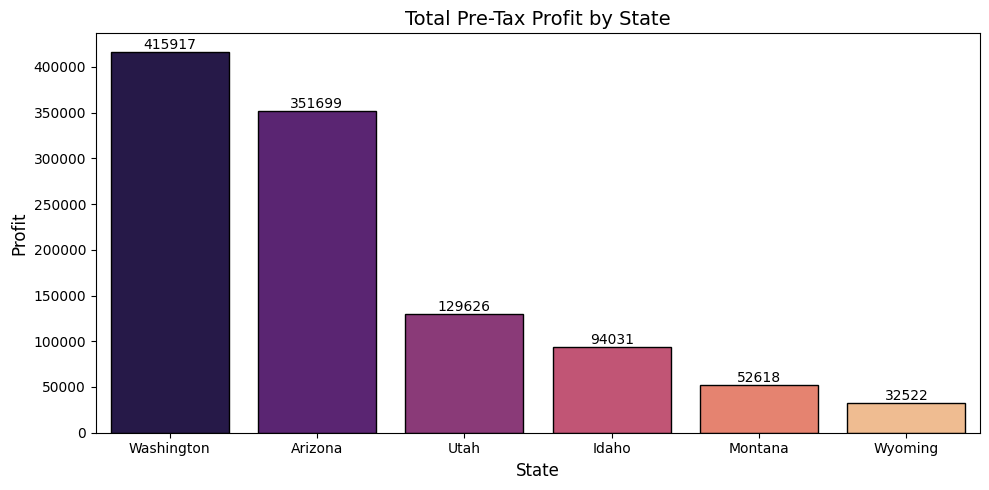

In [11]:

profit_state = (
    df_clean.groupby('State')['Profit']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  

ax1 = sns.barplot(
    data=profit_state,
    x='State',
    y='Profit',
    hue='State',             
    palette='magma',
    legend=False,
    edgecolor='black'
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f')

plt.xlabel("State", fontsize=12)
plt.ylabel("Profit", fontsize=12)
plt.title("Total Pre-Tax Profit by State", fontsize=14)
plt.tight_layout()
plt.show()  

### Interpretation

Washington generated the highest total profit, followed by Arizona.
States with lower total profits contributed significantly less to the company's overall profitability.
This indicates that Trina's strongest financial performance is concentrated in only a few states.

## Actual Total Profit by State

The following chart shows the actual total profit generated in each state.

<Figure size 1000x500 with 0 Axes>

[Text(0, 0, '351699')]

[Text(0, 0, '139864')]

[Text(0, 0, '94031')]

[Text(0, 0, '69443')]

[Text(0, 0, '52618')]

[Text(0, 0, '20525')]

Text(0.5, 0, 'State')

Text(0, 0.5, 'ActualPostTaxProfit')

Text(0.5, 1.0, 'Actual Post-Tax Total Profit by State')

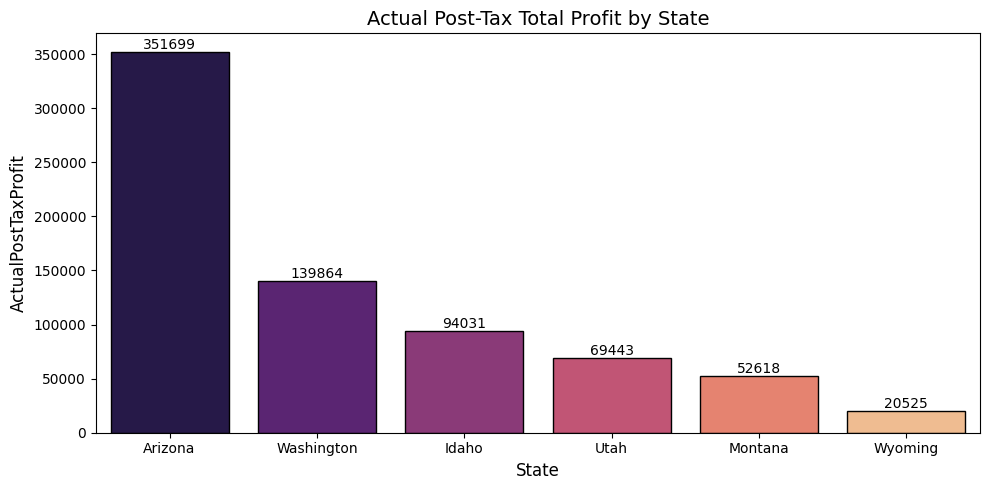

In [12]:
df_clean["ActualPostTaxProfit"] = df_clean["Profit"] - df_clean["SalesTaxOwed"]

profit_state = (
    df_clean.groupby('State')['ActualPostTaxProfit']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))  

ax1 = sns.barplot(
    data=profit_state,
    x='State',
    y='ActualPostTaxProfit',
    hue='State',             
    palette='magma',
    legend=False,
    edgecolor='black'
)

for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f')

plt.xlabel("State", fontsize=12)
plt.ylabel("ActualPostTaxProfit", fontsize=12)
plt.title("Actual Post-Tax Total Profit by State", fontsize=14)
plt.tight_layout()
plt.show()  

### Interpretation



## Average Post-Tax Profit Margin by State

This visualization compares the average post-tax profit margin across all states.

The post-tax profit margin measures how much profit remains after taxes relative to revenue. It provides insight into how efficiently each state converts revenue into profit after accounting for tax obligations.

<Figure size 1000x500 with 0 Axes>

[Text(0, 0, '0.14')]

[Text(0, 0, '0.09')]

[Text(0, 0, '0.08')]

[Text(0, 0, '0.08')]

[Text(0, 0, '0.06')]

[Text(0, 0, '0.05')]

Text(0.5, 1.0, 'Average Post-Tax Profit Margin by State')

Text(0.5, 0, 'State')

Text(0, 0.5, 'Post-Tax Profit Margin')

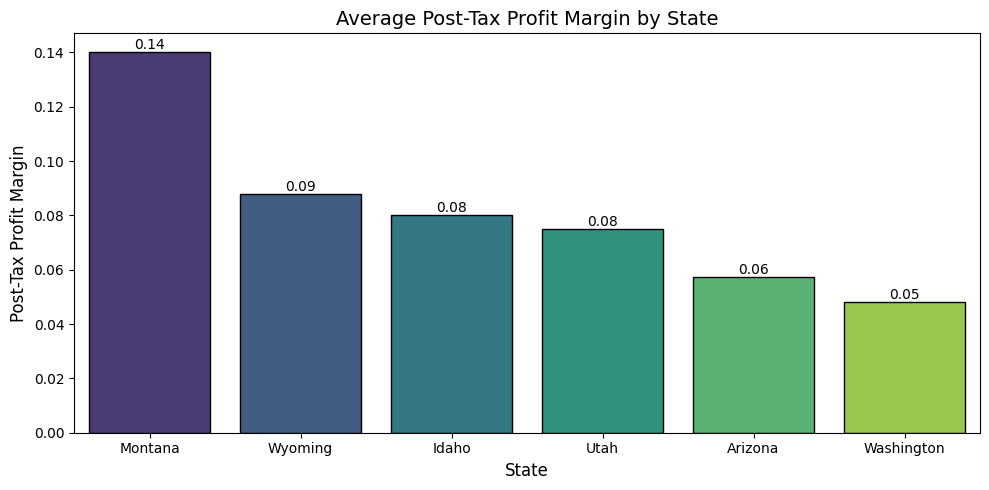

In [13]:
margin_state = (
    df_clean.groupby('State')['PostTaxProfitMargin']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax3 = sns.barplot(
    data=margin_state,
    x='State',
    y='PostTaxProfitMargin',
    hue='State',
    palette='viridis',
    legend=False,
    edgecolor='black'
)

for container in ax3.containers:
    ax3.bar_label(container, fmt='%.2f')

plt.title("Average Post-Tax Profit Margin by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Post-Tax Profit Margin", fontsize=12)
plt.tight_layout()
plt.show()

### Interpretation

The results show noticeable differences in the average post-tax profit margin between states. States with a higher margin retain a larger share of their revenue as profit after taxes, indicating more efficient operations.

Comparing this chart with the revenue and profit visualizations reveals that high revenue alone does not guarantee a high post-tax profit margin. Instead, operational efficiency and the overall tax burden also influence how much profit is ultimately retained.

<Figure size 1000x500 with 0 Axes>

[Text(0, 0, '0.14')]

[Text(0, 0, '0.14')]

[Text(0, 0, '0.14')]

[Text(0, 0, '0.09')]

[Text(0, 0, '0.08')]

[Text(0, 0, '0.05')]

Text(0.5, 1.0, 'Actual Average Post-Tax Profit Margin by State')

Text(0.5, 0, 'State')

Text(0, 0.5, 'Actual Post-Tax Profit Margin')

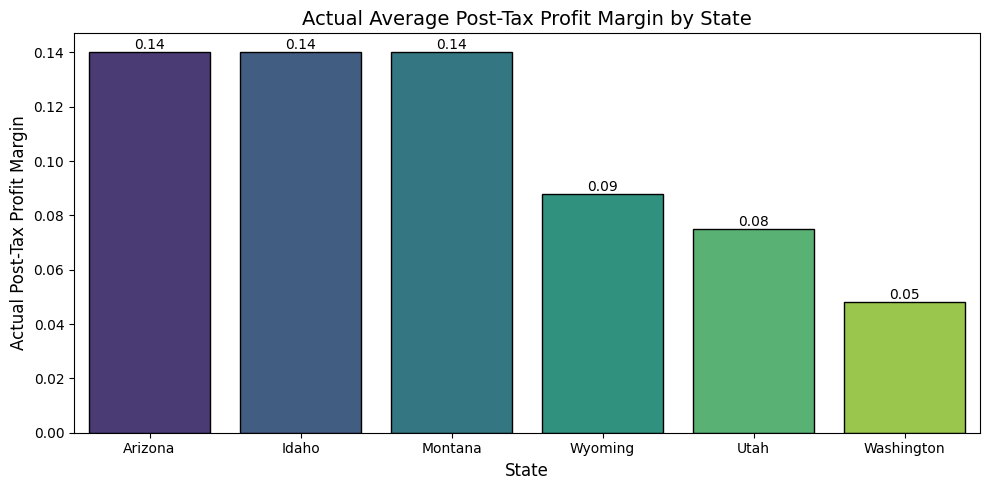

In [14]:
df_clean["ActualPostTaxProfitMargin"] = df_clean["ActualPostTaxProfit"] / df_clean["Revenue"]


margin_state = (
    df_clean.groupby('State')['ActualPostTaxProfitMargin']
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax3 = sns.barplot(
    data=margin_state,
    x='State',
    y='ActualPostTaxProfitMargin',
    hue='State',
    palette='viridis',
    legend=False,
    edgecolor='black'
)

for container in ax3.containers:
    ax3.bar_label(container, fmt='%.2f')

plt.title("Actual Average Post-Tax Profit Margin by State", fontsize=14)
plt.xlabel("State", fontsize=12)
plt.ylabel("Actual Post-Tax Profit Margin", fontsize=12)
plt.tight_layout()
plt.show()

# Data Classification

In [15]:
import pandas as pd
import DataCleaning as df
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Verknüpft mit df_clean
df_classification = df.df_clean

In [16]:
margin_median = df_classification["PostTaxProfitMargin"].median()
print(margin_median)
df.df_clean["HighProfitability"] = (
    df_classification["PostTaxProfitMargin"]
    > margin_median
).astype(int)


print(df_classification["HighProfitability"].value_counts())
# Die zeilen mit Profitabilität werden aufgedeckt 
# 1 = 188692 Zeilen; 0 = 197245

0.05800000000000001
HighProfitability
0    197245
1    188692
Name: count, dtype: int64


In [17]:
feature_columns = [
    "ETR",
    "Revenue"] 
# -> Einzeln abchecken also in 2 aufteieln! weil ETR alle zusammen ist das hier ist jetzt verdoppelt  

feature_columns_tax = [
    "StateRate",
    "EstimatedCountyRate",
    "EstimatedCityRate",
    "EstimatedSpecialRate",
    "Revenue"]    

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",0
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbf

In [66]:
X = df_classification[feature_columns]
y = df_classification["HighProfitability"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12,
    stratify=y
)

In [67]:
fit1 = LogisticRegression(
    random_state=0,
    max_iter=1000
)

fit1.fit(X_train, y_train)

y_pred = fit1.predict(X_test)

In [18]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: ", accuracy)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report( y_test, y_pred))

Accuracy:  0.5565243302067678
Confusion Matrix:
[[22612 16837]
 [17394 20345]]
Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.57      0.57     39449
           1       0.55      0.54      0.54     37739

    accuracy                           0.56     77188
   macro avg       0.56      0.56      0.56     77188
weighted avg       0.56      0.56      0.56     77188



In [69]:
print("Intercept: ")
print(fit1.intercept_)

print("Coefficients: ")
print(fit1.coef_)

Intercept: 
[0.51750924]
Coefficients: 
[[-1.24202103e+01 -1.44803449e-03]]


In [19]:
# Wahrscheinlichkeit für das gesamte Dataset
df_classification["HighProfitabilityProbability"] = (
    fit1.predict_proba(X)[:, 1]
)

# Ergebnisse pro State zusammenfassen
state_results = (
    df_classification.groupby("State")
    .agg(
        AverageProbability=(
            "HighProfitabilityProbability",
            "mean"),

        AveragePostTaxMargin=(
            "PostTaxProfitMargin",
            "mean"),

        TotalProfit=(
            "Profit",
            "sum"),

        TotalRevenue=(
            "Revenue",
            "sum"),

        AverageETR=(
            "ETR",
            "mean"),

        Transactions=(
            "State",
            "size")).reset_index()
)

# Nach Wahrscheinlichkeit für hohe Profitabilität sortieren
state_results = state_results.sort_values(
    by="AverageProbability",
    ascending=False
)

print(state_results)

        State  AverageProbability  AveragePostTaxMargin  TotalProfit  \
2     Montana            0.999939              0.140000   52618.2384   
5     Wyoming            0.984375              0.087788   32521.5380   
1       Idaho            0.915458              0.080000   94031.4592   
3        Utah            0.885211              0.075000  129626.2996   
0     Arizona            0.369582              0.057499  351698.6158   
4  Washington            0.229699              0.048060  415917.0834   

   TotalRevenue  AverageETR  Transactions  
0    2548340.65    0.000000        132421  
1     679567.36    0.000000         34357  
2     381392.82    0.000000         19149  
5     234974.47    0.052204         11419  
3     940318.15    0.068180         52666  
4    3004811.63    0.091954        135925  


In [20]:
state_results["AverageProbability"] = (
    state_results["AverageProbability"] * 100
)

state_results["AveragePostTaxMargin"] = (
    state_results["AveragePostTaxMargin"] * 100
)

state_results["AverageETR"] = (
    state_results["AverageETR"] * 100
)

print(
    state_results.round({
        "AverageProbability": 2,
        "AveragePostTaxMargin": 2,
        "TotalProfit": 2,
        "TotalRevenue": 2,
        "AverageETR": 2
    })
)

print(
    state_results[
        [
            "State",
            "AverageProbability",
            "AveragePostTaxMargin",
            "TotalProfit",
            "TotalRevenue",
            "AverageETR",
            "Transactions"
        ]
    ].to_string(index=False)
)

        State  AverageProbability  AveragePostTaxMargin  TotalProfit  \
2     Montana               99.99                 14.00     52618.24   
5     Wyoming               98.44                  8.78     32521.54   
1       Idaho               91.55                  8.00     94031.46   
3        Utah               88.52                  7.50    129626.30   
0     Arizona               36.96                  5.75    351698.62   
4  Washington               22.97                  4.81    415917.08   

   TotalRevenue  AverageETR  Transactions  
2     375844.56        0.00         19453  
5     232296.70        5.22         11636  
1     671653.28        0.00         35147  
3     925902.14        6.82         53775  
0    2512132.97        0.00        135353  
4    2970836.31        9.19        138649  
     State  AverageProbability  AveragePostTaxMargin  TotalProfit  TotalRevenue  AverageETR  Transactions
   Montana           99.993920             14.000000   52618.2384     375844.56  

## Clustering: Tax Profile and Profitability Across States

In this section we group Trina's transactions using K-Means based on their tax profile
(state, county, city and special tax rates). The goal is to understand whether the
states can be separated into clearly distinct groups by their tax burden, and how these
groups differ in their post-tax profit margin. This addresses Trina's core question of
where she operates most profitably.

In [21]:
# Safety step: remove whitespace in 'State' (in case it wasn't done during cleaning)
df_clean["State"] = df_clean["State"].str.strip()

# Features: state (categorical) + the four tax rates
short = df_clean[["State",
                  "StateRate",
                  "EstimatedCountyRate",
                  "EstimatedCityRate",
                  "EstimatedSpecialRate"]]

# K-Means needs numbers -> convert the categorical column 'State' into dummy variables
short_dummys = pd.get_dummies(short)
short_dummys.columns.tolist()

['StateRate',
 'EstimatedCountyRate',
 'EstimatedCityRate',
 'EstimatedSpecialRate',
 'State_Arizona',
 'State_Idaho',
 'State_Montana',
 'State_Utah',
 'State_Washington',
 'State_Wyoming']

,PostTaxProfitIfNexus,PostTaxProfitMargin,EstimatedCombinedRate,Cluster
0,141791.793548,0.052779,0.087221,0
1,46914.872105,0.080929,0.059071,1
2,52618.238400,0.140000,0.000000,2


,Cluster,PostTaxProfitIfNexus,PostTaxProfitMargin,EstimatedCombinedRate,State
0,0,141791.793548,0.052779,0.087221,"Arizona, Washington"
1,1,46914.872105,0.080929,0.059071,"Idaho, Utah, Wyoming"
2,2,52618.238400,0.140000,0.000000,Montana


,PostTaxProfitIfNexus,PostTaxProfitMargin,EstimatedCombinedRate
Cluster,,,
0,1.348746,-0.971846,0.971846
1,-0.705241,-0.015684,0.015684
2,-0.581769,1.990744,-1.990744


<Figure size 1000x400 with 0 Axes>

K-Means can only work with numerical values. We therefore convert the text column
`State` into six 0/1 columns using `pd.get_dummies()` (e.g. `State_Montana`). The four
tax rates all lie in a range of roughly 0 to 0.065 and are therefore naturally
comparable, so no additional scaling is required.

In [73]:
# K-Means clustering (parameters as used in the lecture)
kmeans = KMeans(n_clusters=4, max_iter=1000, random_state=12)
kmeans.fit(short_dummys)
df_clean["Cluster"] = kmeans.labels_

# Centroids = average profile of each cluster
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=short_dummys.columns)
print(centroids.round(3))
print(df_clean["Cluster"].value_counts())

   StateRate  EstimatedCountyRate  EstimatedCityRate  EstimatedSpecialRate  \
0      0.065                0.003              0.023                 0.001   
1      0.057                0.006              0.015                -0.000   
2      0.046                0.004              0.008                 0.005   
3     -0.000               -0.000              0.000                 0.000   

   State_Arizona  State_Idaho  State_Montana  State_Utah  State_Washington  \
0         -0.000       -0.000           -0.0       0.000               1.0   
1          0.794        0.206           -0.0       0.000               0.0   
2         -0.000       -0.000            0.0       0.822              -0.0   
3         -0.000        0.000            1.0      -0.000               0.0   

   State_Wyoming  
0         -0.000  
1         -0.000  
2          0.178  
3          0.000  
Cluster
1    166778
0    135925
2     64085
3     19149
Name: count, dtype: int64


We form four clusters. Each transaction is assigned a cluster number, and the centroids
show the average tax and state profile of each group. The four clusters are reasonably
balanced in size, which indicates a meaningful grouping.

<Axes: ylabel='Cluster'>

Text(0.5, 1.0, 'Cluster Profiles Based on Nexus-Adjusted Profitability')

Text(0.5, 14.722222222222216, 'Feature')

Text(95.72222222222221, 0.5, 'Cluster')

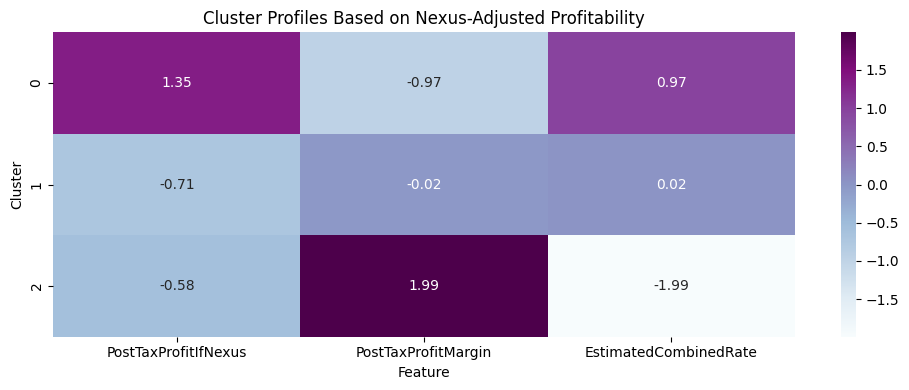

In [74]:
# Heatmap of the cluster profiles (as in the lecture)
plt.rcParams["figure.figsize"] = (10, 4)
sns.heatmap(centroids, annot=True, cmap="BuPu", fmt=".3f")
plt.title("Tax Profile and State per Cluster")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()

**Interpretation of the heatmap:** Each cluster row is dominated by exactly one state
(dark cell in the state columns). The cluster containing Montana shows a value of zero
for all tax rates and therefore represents the tax-free zone. The cluster containing
Washington has the highest city tax. The clustering thus clearly separates the states
by their tax burden.

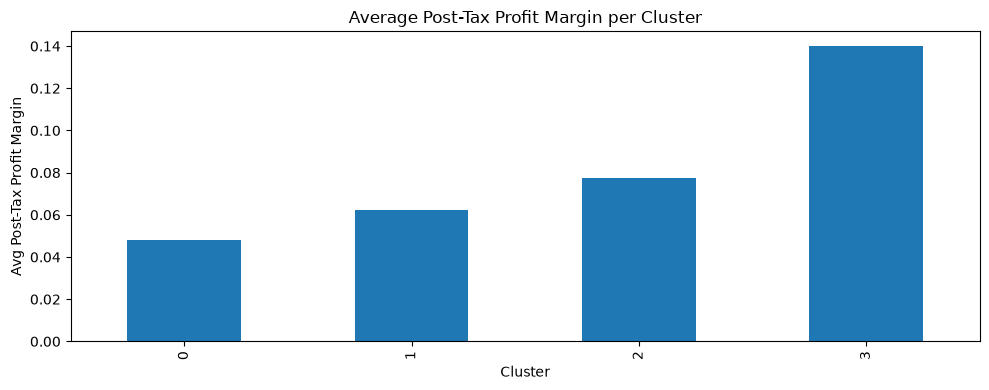

In [75]:
# Average post-tax profit margin per cluster (as in the lecture)
df_clean.groupby("Cluster")["PostTaxProfitMargin"].mean().plot(kind="bar")
plt.title("Average Post-Tax Profit Margin per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Avg Post-Tax Profit Margin")
plt.tight_layout()

**Interpretation of the bar chart:** There is a clear relationship between tax burden
and profitability. The cluster containing Montana (tax-free) reaches the highest
post-tax margin at around 14%, while the cluster containing Washington (highest tax
burden) reaches the lowest at around 4.8%. For Trina this means that states with a lower
tax burden are considerably more profitable and should be prioritized when expanding.
The location is therefore the decisive lever for Trina's profitability.

# The Forecast

,State,InvoiceYear,InvoiceMonth,ActualPostTaxProfit,PostTaxProfitIfNexus
0,Arizona,2016,12,23163.36260,9460.597286
1,Arizona,2017,1,18666.83280,7637.614344
2,Arizona,2017,2,18233.89820,7410.292671
3,Arizona,2017,3,22879.60640,9390.564518
4,Arizona,2017,4,20440.23800,8441.795465
...,...,...,...,...,...
73,Wyoming,2017,8,1182.36810,1182.368100
74,Wyoming,2017,9,2566.68060,2566.680600
75,Wyoming,2017,10,2547.08345,2547.083450
76,Wyoming,2017,11,2666.33830,2666.338300


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1449.96]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[18353.96]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[590.29]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[7513.66]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


c:\Users\yjewa_dkcbooz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
c:\Users\yjewa_dkcbooz\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[295.39]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[5460.86]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[168.79]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3120.49]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


... (18 outputs left out)

<Axes: xlabel='State'>

Text(0.5, 0, 'State')

Text(0, 0.5, 'Relative Growth in %')

Text(0.5, 1.0, 'Relative profit growth by state')

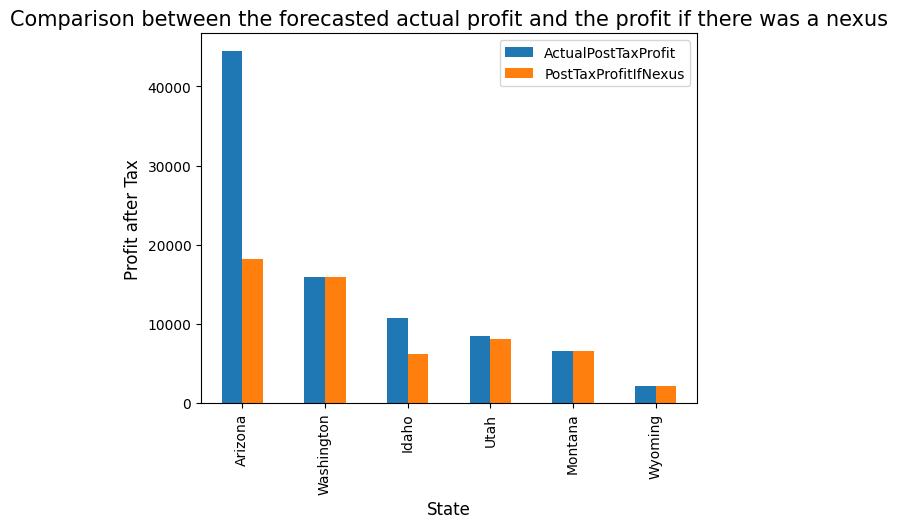

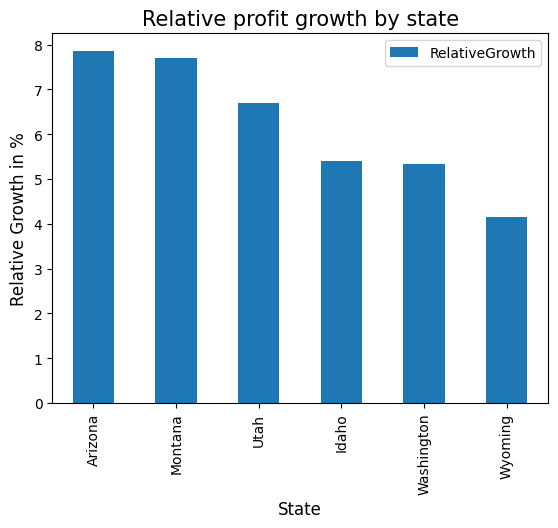

In [ ]:
df_clean["InvoiceMonth"] = pd.to_datetime(df_clean["InvoiceDate"]).dt.month #create a month variable for the linear Regression
# variables for the posttaxprofit
df_clean["PostTaxProfitIfNexus"] = df_clean["Profit"]-df_clean["SalesTaxNoNexus"] 
df_clean["ActualPostTaxProfit"] = df_clean["Profit"] - df_clean["SalesTaxOwed"]
# group dataframe for linear regression
df_grouped = df_clean.groupby(by=["State", "InvoiceYear", "InvoiceMonth"])[["ActualPostTaxProfit", "PostTaxProfitIfNexus"]].sum().reset_index()
df_grouped
growth_trends = []

# loop to predict the profit for all states
for state in df_grouped["State"].unique():
    df_state = df_grouped.loc[df_grouped["State"] == state].copy()
    # add the time index
    df_state["time"] = range(len(df_state))
    
    #predict profit for the actual profit
    model_actual = linear_model.LinearRegression()
    model_actual.fit(df_state[["time"]], df_state[["ActualPostTaxProfit"]])
    actual_post_tax_profit_growth = model_actual.coef_[0][0]
    
    #predict profit for the profitif there was a nexus
    model_ifnexus = linear_model.LinearRegression()
    model_ifnexus.fit(df_state[["time"]], df_state[["PostTaxProfitIfNexus"]])
    post_tax_profit_ifnexus_growth = model_ifnexus.coef_[0][0]
    ifnexus_intercept = model_ifnexus.intercept_[0]

    # determine the relative growth
    relative_growth = post_tax_profit_ifnexus_growth / ifnexus_intercept *100

    # prediction for in 6 months
    six_month_prediction = len(df_state)+5
    # save and append the predictions and the growth in the list
    growth_trends.append({
        "State": state,
        "ActualPostTaxProfit": model_actual.predict([[six_month_prediction]])[0][0],
        "ActualPostTaxProfitGrowth": actual_post_tax_profit_growth,
        "PostTaxProfitIfNexus": model_ifnexus.predict([[six_month_prediction]])[0][0],
        "PostTaxProfitIfNexusGrowth": post_tax_profit_ifnexus_growth,
        "RelativeGrowth": relative_growth
    })


# put list into dataframe
df_trends = pd.DataFrame(growth_trends)
df_trends = df_trends.sort_values(by=("ActualPostTaxProfit"), ascending=False)
df_trends
#create a multiple bar diagram to compare the profits 
df_trends.plot(kind="bar",x="State", y=["ActualPostTaxProfit", "PostTaxProfitIfNexus"])

plt.xlabel("State", fontsize =12)
plt.ylabel("Profit after Tax", fontsize = 12)
plt.title("Comparison between the forecasted actual profit and the profit if there was a nexus", fontsize =15)

# display the relative profit growth
df_trends = df_trends.sort_values(by=("RelativeGrowth"), ascending=False)
df_trends.plot(kind="bar",x="State", y="RelativeGrowth")

plt.xlabel("State", fontsize =12)
plt.ylabel("Relative Growth in %", fontsize = 12)
plt.title("Relative profit growth by state", fontsize =15)

                                             


